# Ajustes NOGSE libres: Hahn, CPMG y contraste

Notebook sencillo para el fantoma de agua de Capiglioni *et al.*. Lee directamente `master.long.parquet`, ajusta solo $D_0$ (con $M_0=1$) y guarda todas las figuras y tablas en `signal_analysis/fittings/`.

El modelo libre es $S/S_0=\exp(-b_{NOGSE}D_0)$. Se usa el `bvalue` exacto de la forma de onda trapezoidal guardado en la tabla (incluye las rampas de 1.2 ms), no la aproximación de lóbulos rectangulares. El contraste se define como $M_{CPMG}-M_{Hahn}$ y usa por separado los valores $b$ reales de ambas adquisiciones; Hahn tiene `x=5 ms`, no `x=0`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize_scalar


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'Data-BIDS').is_dir() and (candidate / 'repos' / 'signal_analysis').is_dir():
            return candidate
    raise FileNotFoundError('No encuentro la raíz del proyecto.')


PROJECT_ROOT = find_project_root()
REPO_ROOT = PROJECT_ROOT / 'repos' / 'signal_analysis'
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
PROJECT_ROOT

PosixPath('/mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE')

## Configuración

Por defecto se usa la rama denoised + Gibbs-removal (`den_gr--manual`). Cambiar solo `ANALYSIS_TAG` permite repetir exactamente el análisis con `raw--manual`.

In [2]:
ANALYSIS_TAG = 'den_gr--manual'  # alternativa: 'raw--manual'
ROI = 'water'
STAT = 'avg'
D0_BOUNDS_MM2_S = (1e-4, 1e-2)

MASTER_PATH = (PROJECT_ROOT / 'Data-BIDS' / 'derivatives' / 'signal_analysis' /
               ANALYSIS_TAG / 'phantoms' / 'nogse_experiments' / 'master.long.parquet')
OUTPUT_ROOT = REPO_ROOT / 'fittings'
SIGNAL_DIR = OUTPUT_ROOT / 'signals'
CONTRAST_DIRECTION_DIR = OUTPUT_ROOT / 'contrasts_by_direction'
CONTRAST_TIME_DIR = OUTPUT_ROOT / 'contrasts_by_time'
TABLE_DIR = OUTPUT_ROOT / 'tables'
for folder in (SIGNAL_DIR, CONTRAST_DIRECTION_DIR, CONTRAST_TIME_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

master = pd.read_parquet(MASTER_PATH)
data = master.loc[(master['stat'].astype(str) == STAT) &
                  (master['roi'].astype(str) == ROI) &
                  (master['type'].astype(str).str.upper().isin(['CPMG', 'HAHN']))].copy()
data['type'] = data['type'].astype(str).str.upper()
data['direction'] = data['direction'].astype(str)
for column in ['td_ms', 'N', 'x', 'g', 'bvalue', 'b_step', 'value_norm']:
    data[column] = pd.to_numeric(data[column], errors='coerce')
data = data.dropna(subset=['td_ms', 'N', 'x', 'g', 'bvalue', 'b_step', 'value_norm'])

print('Master:', MASTER_PATH)
print('Salida:', OUTPUT_ROOT)
display(data.groupby(['type', 'td_ms', 'direction']).size().rename('n').reset_index())

Master: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/Data-BIDS/derivatives/signal_analysis/den_gr--manual/phantoms/nogse_experiments/master.long.parquet
Salida: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/fittings


,type,td_ms,direction,n
0,CPMG,30.0,1,11
1,CPMG,30.0,2,11
2,CPMG,30.0,3,11
3,CPMG,40.0,1,11
4,CPMG,40.0,2,11
5,CPMG,40.0,3,11
6,CPMG,50.0,1,11
7,CPMG,50.0,2,11
8,CPMG,50.0,3,11
9,CPMG,70.0,1,11


## Funciones de modelo y ajuste

Se minimiza el error cuadrático en escala de señal normalizada. Como `value_norm` vale 1 en $G=0$, se fija $M_0=1$. El ajuste se hace sobre el logaritmo de $D_0$ para mantener $D_0>0$.

In [3]:
def signal_model(b_s_mm2, d0_mm2_s):
    return np.exp(-np.asarray(b_s_mm2, float) * float(d0_mm2_s))


def b_per_g2(curve, b_column='bvalue'):
    positive = curve['g'].to_numpy(float) > 0
    return float(np.median(curve.loc[positive, b_column] / curve.loc[positive, 'g']**2))


def fit_one_parameter(y, model):
    y = np.asarray(y, float)
    valid = np.isfinite(y)
    lo, hi = np.log(D0_BOUNDS_MM2_S)

    def loss(log_d0):
        prediction = np.asarray(model(np.exp(log_d0)), float)
        return np.mean((y[valid] - prediction[valid]) ** 2)

    result = minimize_scalar(loss, bounds=(lo, hi), method='bounded')
    d0 = float(np.exp(result.x))
    prediction = np.asarray(model(d0), float)
    residual = y[valid] - prediction[valid]
    return {
        'D0_mm2_s': d0,
        'rmse': float(np.sqrt(np.mean(residual**2))),
        'n_points': int(valid.sum()),
        'ok': bool(result.success),
    }


def d0_label(d0):
    return f'$D_0$={d0 * 1e3:.3f} × 10$^{{-3}}$ mm²/s'


def save_figure(fig, folder, stem):
    fig.savefig(folder / f'{stem}.png', dpi=180, bbox_inches='tight')
    fig.savefig(folder / f'{stem}.pdf', bbox_inches='tight')

## Hahn y CPMG: una figura por medición

Cada figura contiene las tres direcciones y su propio $D_0$ ajustado. Se generan ocho figuras: Hahn y CPMG para cada uno de los cuatro tiempos.

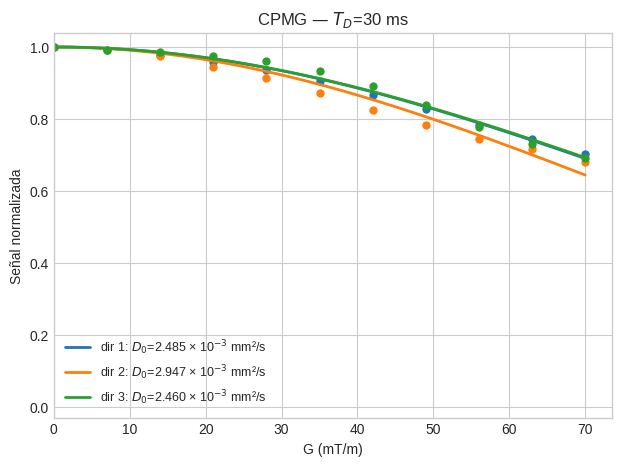

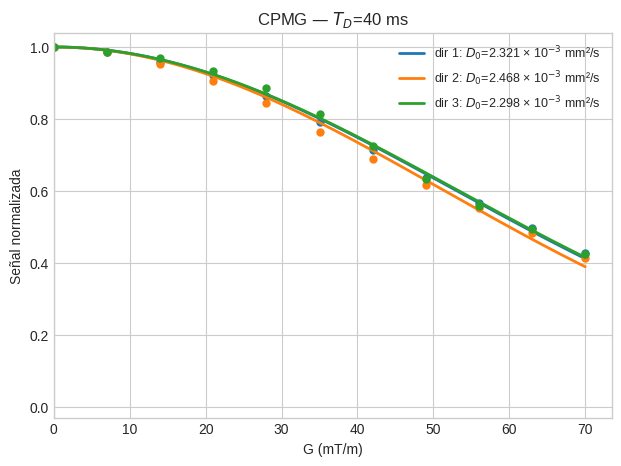

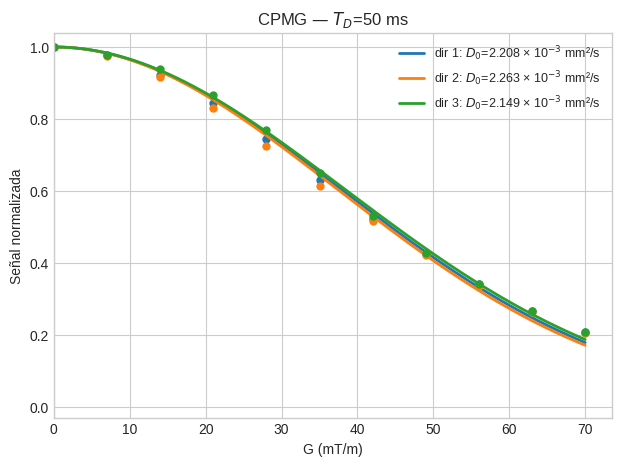

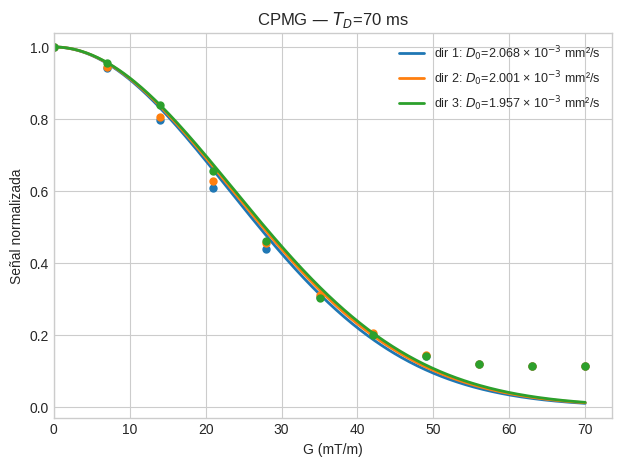

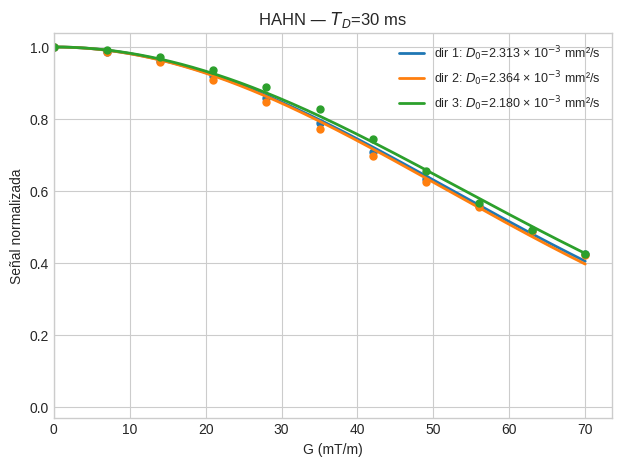

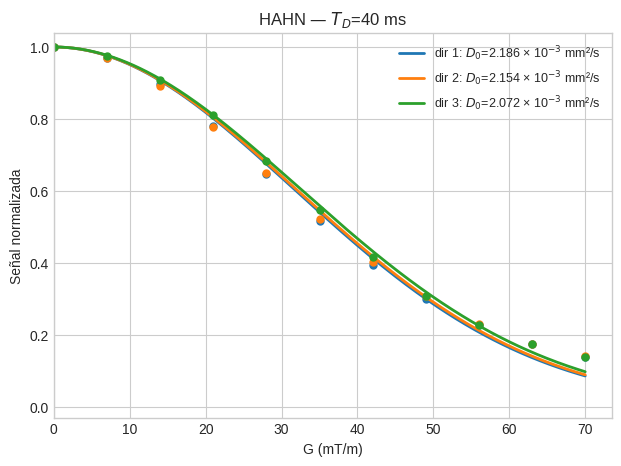

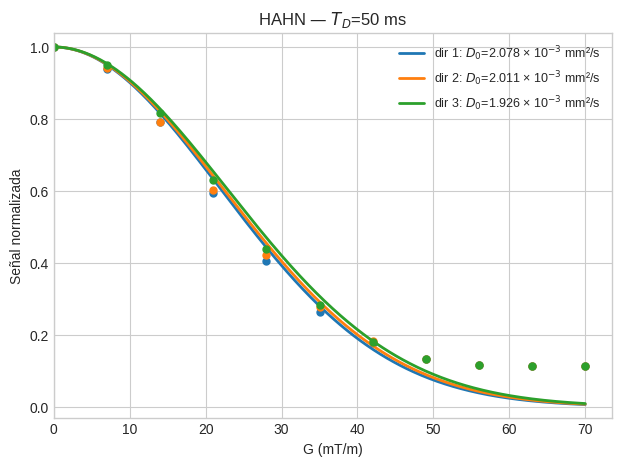

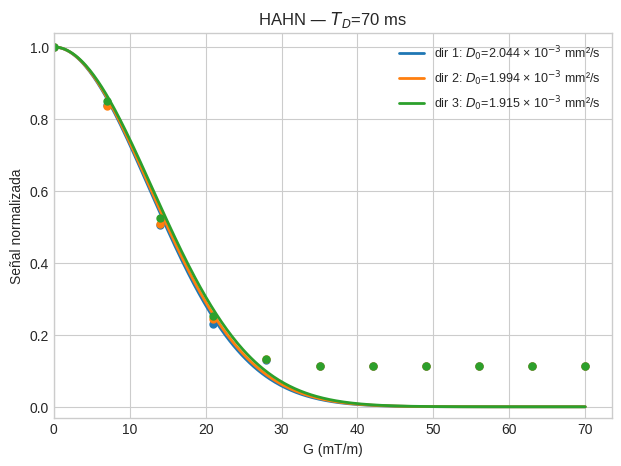

,analysis_tag,roi,type,td_ms,direction,N,x_ms,D0_mm2_s,rmse,n_points,ok
0,den_gr--manual,water,CPMG,30.0,1,2.0,15.0,0.002485,0.006710,11,True
1,den_gr--manual,water,CPMG,30.0,2,2.0,15.0,0.002947,0.019136,11,True
2,den_gr--manual,water,CPMG,30.0,3,2.0,15.0,0.002460,0.011011,11,True
3,den_gr--manual,water,CPMG,40.0,1,2.0,20.0,0.002321,0.008369,11,True
4,den_gr--manual,water,CPMG,40.0,2,2.0,20.0,0.002468,0.016081,11,True
5,den_gr--manual,water,CPMG,40.0,3,2.0,20.0,0.002298,0.009748,11,True
6,den_gr--manual,water,CPMG,50.0,1,2.0,25.0,0.002208,0.015234,11,True
7,den_gr--manual,water,CPMG,50.0,2,2.0,25.0,0.002263,0.020417,11,True
8,den_gr--manual,water,CPMG,50.0,3,2.0,25.0,0.002149,0.010085,11,True
9,den_gr--manual,water,CPMG,70.0,1,2.0,35.0,0.002068,0.052705,11,True


In [4]:
direction_colors = {'1': 'tab:blue', '2': 'tab:orange', '3': 'tab:green'}
signal_fit_rows = []

for (sequence_type, td_ms), measurement in data.groupby(['type', 'td_ms'], sort=True):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    for direction, curve in measurement.groupby('direction', sort=True):
        curve = curve.sort_values('g')
        g = curve['g'].to_numpy(float)
        b = curve['bvalue'].to_numpy(float)
        y = curve['value_norm'].to_numpy(float)
        n_value = float(curve['N'].iloc[0])
        x_ms = float(curve['x'].iloc[0])
        fit = fit_one_parameter(y, lambda d0: signal_model(b, d0))
        signal_fit_rows.append({
            'analysis_tag': ANALYSIS_TAG, 'roi': ROI, 'type': sequence_type,
            'td_ms': td_ms, 'direction': direction, 'N': n_value, 'x_ms': x_ms, **fit
        })
        color = direction_colors.get(direction)
        ax.plot(g, y, 'o', color=color, ms=5)
        g_fine = np.linspace(0, g.max(), 400)
        b_fine = b_per_g2(curve) * g_fine**2
        ax.plot(g_fine, signal_model(b_fine, fit['D0_mm2_s']),
                color=color, lw=2, label=f'dir {direction}: {d0_label(fit["D0_mm2_s"])}')
    ax.set(title=f'{sequence_type} — $T_D$={td_ms:g} ms', xlabel='G (mT/m)',
           ylabel='Señal normalizada', xlim=(0, None), ylim=(-0.03, 1.04))
    ax.legend(fontsize=9)
    save_figure(fig, SIGNAL_DIR, f'signal_{sequence_type}_Td-{td_ms:g}ms')
    plt.show()

signal_fits = pd.DataFrame(signal_fit_rows).sort_values(['type', 'td_ms', 'direction'])
signal_fits.to_csv(TABLE_DIR / 'signal_fits.csv', index=False)
display(signal_fits)

## Construcción y ajuste del contraste CPMG − Hahn

Las curvas se emparejan estrictamente por tiempo, dirección y `b_step`. También se verifica que los valores de $G$ coincidan. Cada combinación tiempo-dirección tiene un único ajuste de $D_0$, reutilizado en las dos galerías siguientes.

In [5]:
keys = ['td_ms', 'direction', 'b_step']
keep = keys + ['g', 'bvalue', 'N', 'x', 'value_norm']
cpmg = data.loc[data['type'].eq('CPMG'), keep].rename(columns={c: f'{c}_cpmg' for c in ['g', 'bvalue', 'N', 'x', 'value_norm']})
hahn = data.loc[data['type'].eq('HAHN'), keep].rename(columns={c: f'{c}_hahn' for c in ['g', 'bvalue', 'N', 'x', 'value_norm']})
contrast = cpmg.merge(hahn, on=keys, how='inner', validate='one_to_one')
if not np.allclose(contrast['g_cpmg'], contrast['g_hahn'], rtol=1e-6, atol=1e-6):
    raise ValueError('CPMG y Hahn no tienen el mismo G para todos los puntos emparejados.')
if not np.allclose(contrast['N_cpmg'], contrast['N_hahn']):
    raise ValueError('CPMG y Hahn no tienen el mismo N.')
contrast['g'] = contrast['g_cpmg']
contrast['value_contrast'] = contrast['value_norm_cpmg'] - contrast['value_norm_hahn']

def contrast_model(b_cpmg, b_hahn, d0):
    return signal_model(b_cpmg, d0) - signal_model(b_hahn, d0)

contrast_fit_rows = []
for (td_ms, direction), curve in contrast.groupby(['td_ms', 'direction'], sort=True):
    curve = curve.sort_values('g')
    row = curve.iloc[0]
    g = curve['g'].to_numpy(float)
    y = curve['value_contrast'].to_numpy(float)
    b_cpmg = curve['bvalue_cpmg'].to_numpy(float)
    b_hahn = curve['bvalue_hahn'].to_numpy(float)
    fit = fit_one_parameter(y, lambda d0: contrast_model(b_cpmg, b_hahn, d0))
    contrast_fit_rows.append({
        'analysis_tag': ANALYSIS_TAG, 'roi': ROI, 'td_ms': td_ms, 'direction': direction,
        'N': row.N_cpmg, 'x_cpmg_ms': row.x_cpmg, 'x_hahn_ms': row.x_hahn, **fit
    })

contrast_fits = pd.DataFrame(contrast_fit_rows).sort_values(['td_ms', 'direction'])
contrast_fits.to_csv(TABLE_DIR / 'contrast_fits.csv', index=False)
display(contrast_fits)

,analysis_tag,roi,td_ms,direction,N,x_cpmg_ms,x_hahn_ms,D0_mm2_s,rmse,n_points,ok
0,den_gr--manual,water,30.0,1,2,15.0,5.0,0.002102,0.005995,11,True
1,den_gr--manual,water,30.0,2,2,15.0,5.0,0.001689,0.004248,11,True
2,den_gr--manual,water,30.0,3,2,15.0,5.0,0.001891,0.005846,11,True
3,den_gr--manual,water,40.0,1,2,20.0,5.0,0.002598,0.023581,11,True
4,den_gr--manual,water,40.0,2,2,20.0,5.0,0.002134,0.040621,11,True
5,den_gr--manual,water,40.0,3,2,20.0,5.0,0.002448,0.030055,11,True
6,den_gr--manual,water,50.0,1,2,25.0,5.0,0.002852,0.021907,11,True
7,den_gr--manual,water,50.0,2,2,25.0,5.0,0.002831,0.036840,11,True
8,den_gr--manual,water,50.0,3,2,25.0,5.0,0.002792,0.025767,11,True
9,den_gr--manual,water,70.0,1,2,35.0,5.0,0.002855,0.025428,11,True


## Contrastes: cuatro tiempos para cada dirección

Cada figura tiene exactamente cuatro curvas, una para cada tiempo disponible.

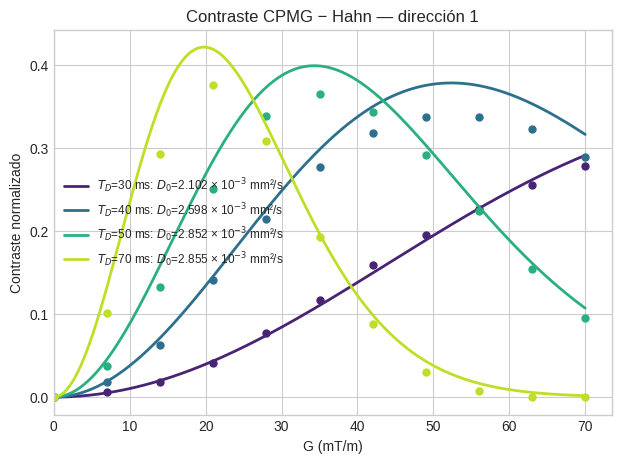

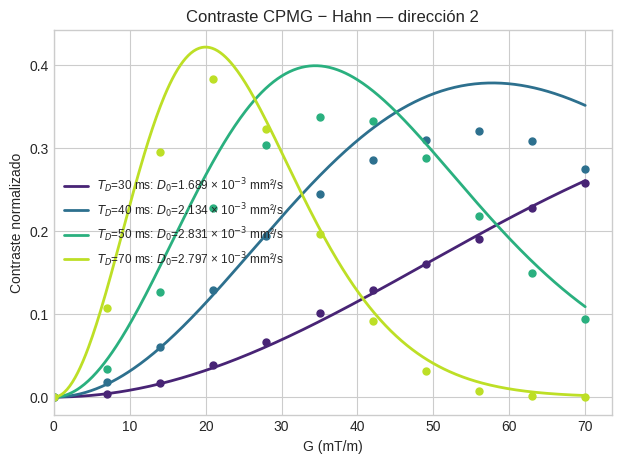

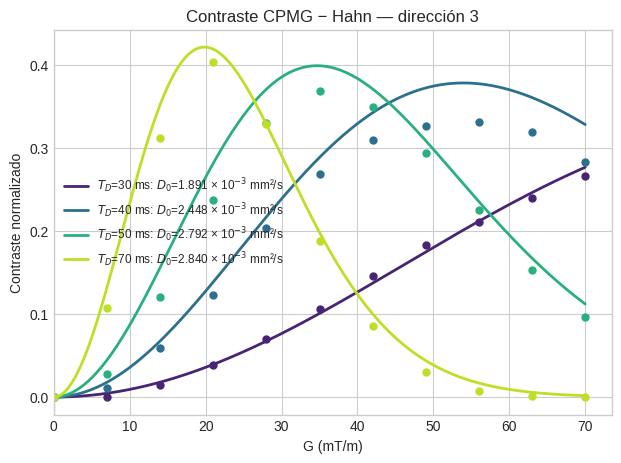

In [6]:
time_colors = dict(zip(sorted(contrast['td_ms'].unique()), plt.cm.viridis(np.linspace(0.1, 0.9, contrast['td_ms'].nunique()))))

for direction, panel in contrast.groupby('direction', sort=True):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    for td_ms, curve in panel.groupby('td_ms', sort=True):
        curve = curve.sort_values('g')
        row = curve.iloc[0]
        fit = contrast_fits.loc[(contrast_fits['td_ms'].eq(td_ms)) &
                                (contrast_fits['direction'].eq(direction))].iloc[0]
        color = time_colors[td_ms]
        ax.plot(curve['g'], curve['value_contrast'], 'o', color=color, ms=5)
        g_fine = np.linspace(0, curve['g'].max(), 400)
        positive = curve['g'] > 0
        k_cpmg = float(np.median(curve.loc[positive, 'bvalue_cpmg'] / curve.loc[positive, 'g']**2))
        k_hahn = float(np.median(curve.loc[positive, 'bvalue_hahn'] / curve.loc[positive, 'g']**2))
        ax.plot(g_fine, contrast_model(k_cpmg * g_fine**2, k_hahn * g_fine**2, fit.D0_mm2_s), color=color, lw=2,
                label=f'$T_D$={td_ms:g} ms: {d0_label(fit.D0_mm2_s)}')
    ax.set(title=f'Contraste CPMG − Hahn — dirección {direction}', xlabel='G (mT/m)',
           ylabel='Contraste normalizado', xlim=(0, None))
    ax.legend(fontsize=8.5)
    save_figure(fig, CONTRAST_DIRECTION_DIR, f'contrast_direction-{direction}')
    plt.show()

## Contrastes: mismo tiempo y distinta dirección

Esta galería muestra directamente cuánto coinciden (o no) las tres direcciones a cada tiempo.

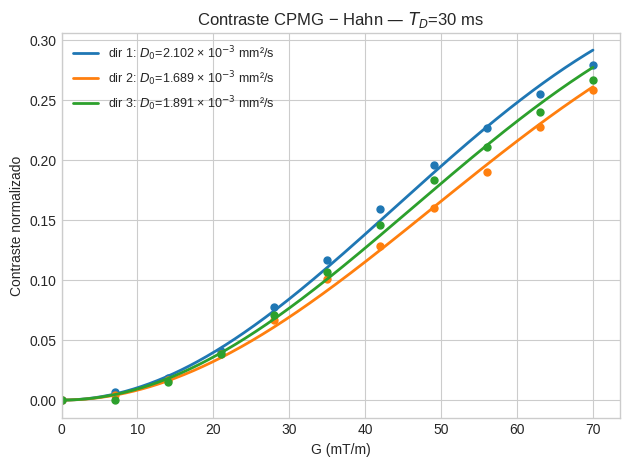

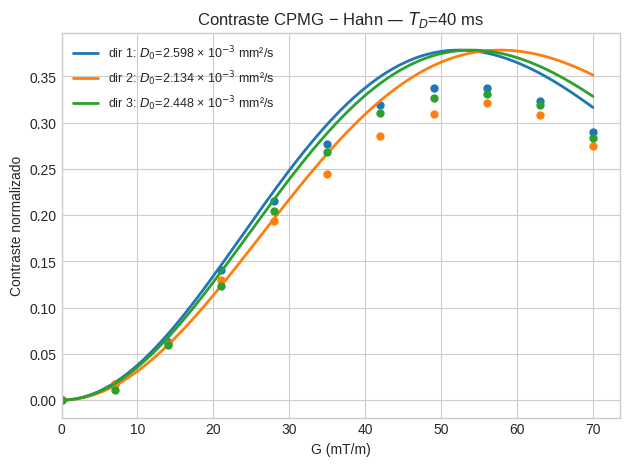

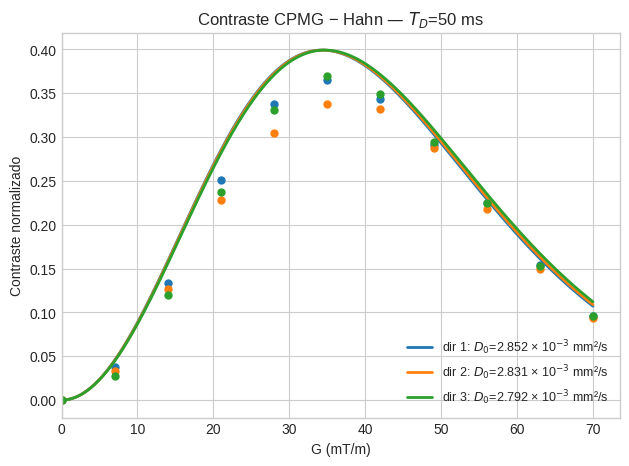

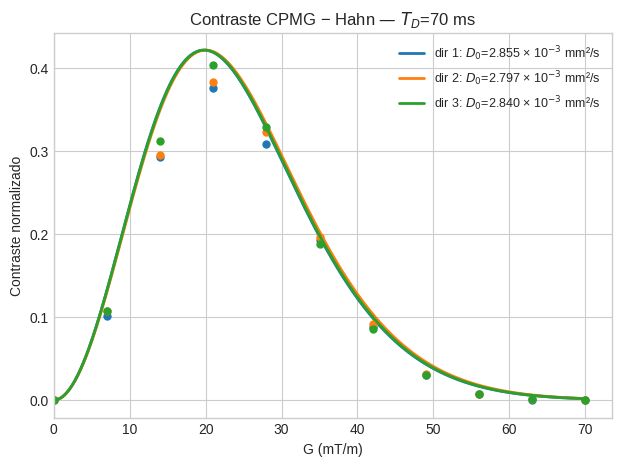

In [7]:
for td_ms, panel in contrast.groupby('td_ms', sort=True):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    for direction, curve in panel.groupby('direction', sort=True):
        curve = curve.sort_values('g')
        row = curve.iloc[0]
        fit = contrast_fits.loc[(contrast_fits['td_ms'].eq(td_ms)) &
                                (contrast_fits['direction'].eq(direction))].iloc[0]
        color = direction_colors.get(direction)
        ax.plot(curve['g'], curve['value_contrast'], 'o', color=color, ms=5)
        g_fine = np.linspace(0, curve['g'].max(), 400)
        positive = curve['g'] > 0
        k_cpmg = float(np.median(curve.loc[positive, 'bvalue_cpmg'] / curve.loc[positive, 'g']**2))
        k_hahn = float(np.median(curve.loc[positive, 'bvalue_hahn'] / curve.loc[positive, 'g']**2))
        ax.plot(g_fine, contrast_model(k_cpmg * g_fine**2, k_hahn * g_fine**2, fit.D0_mm2_s), color=color, lw=2,
                label=f'dir {direction}: {d0_label(fit.D0_mm2_s)}')
    ax.set(title=f'Contraste CPMG − Hahn — $T_D$={td_ms:g} ms', xlabel='G (mT/m)',
           ylabel='Contraste normalizado', xlim=(0, None))
    ax.legend(fontsize=9)
    save_figure(fig, CONTRAST_TIME_DIR, f'contrast_Td-{td_ms:g}ms')
    plt.show()

## Diagnóstico de las diferencias entre direcciones

`max_direction_range` es la máxima separación absoluta entre las tres curvas medidas a un mismo $G$. `rms_direction_spread` resume la dispersión respecto de la media direccional. Estos valores se calculan antes del ajuste. `D0_cv_percent` cuantifica la variación de los $D_0$ ajustados entre direcciones.

In [8]:
qc_rows = []
for (sequence_type, td_ms), panel in data.groupby(['type', 'td_ms'], sort=True):
    wide = panel.pivot(index='b_step', columns='direction', values='value_norm')
    point_ranges = wide.max(axis=1) - wide.min(axis=1)
    point_spread = wide.sub(wide.mean(axis=1), axis=0)
    fitted = signal_fits.loc[(signal_fits['type'].eq(sequence_type)) & signal_fits['td_ms'].eq(td_ms), 'D0_mm2_s']
    qc_rows.append({
        'type': sequence_type, 'td_ms': td_ms,
        'max_direction_range': float(point_ranges.max()),
        'rms_direction_spread': float(np.sqrt(np.nanmean(point_spread.to_numpy()**2))),
        'D0_mean_mm2_s': float(fitted.mean()),
        'D0_cv_percent': float(100 * fitted.std(ddof=1) / fitted.mean()),
    })

direction_qc = pd.DataFrame(qc_rows)
direction_qc.to_csv(TABLE_DIR / 'direction_qc.csv', index=False)
display(direction_qc)
print('Figuras y tablas guardadas en:', OUTPUT_ROOT)

,type,td_ms,max_direction_range,rms_direction_spread,D0_mean_mm2_s,D0_cv_percent
0,CPMG,30.0,0.065903,0.016338,0.002631,10.415577
1,CPMG,40.0,0.049924,0.010808,0.002363,3.901555
2,CPMG,50.0,0.044672,0.009130,0.002207,2.583075
3,CPMG,70.0,0.048891,0.008923,0.002009,2.792422
4,HAHN,30.0,0.053666,0.012321,0.002285,4.162184
5,HAHN,40.0,0.034245,0.008523,0.002137,2.749052
6,HAHN,50.0,0.036381,0.007786,0.002005,3.807425
7,HAHN,70.0,0.021609,0.004191,0.001984,3.288886


Figuras y tablas guardadas en: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/fittings
